> **中文阅读版**：本文件是 `01_sec_filing_pipeline.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 在建立索引前剖析申报文件语料库

**第 22 章：面向金融研究的 RAG**

## 目的

本章的七个 notebook 都围绕同一个年报语料库进行检索。它们所能展示的一切都受限于该语料库包含的内容，而其中的四个属性会改变索引的构建方式。这四个属性中没有一个能通过行数看出来。

第一个是每份金融文档都具有的时间属性：一份 10-K 描述的是在文件公开前数周已经结束的财年，因此用于过滤的日期并不是报告所涉及的日期。第二个是键控属性：同一家公司可能以两个股票代码 (ticker) 进入语料库，而以股票代码为键的检索器会把同一份文档返回两次。第三个是覆盖属性：缺失的代码-年份 (symbol-year) 在查询时不会产生错误，只会给出一个自信的答案，而该答案取自另一家公司的申报文件。第四个是存储文本究竟是什么：既不是整份申报文件，也不是其开头页面，而是下载程序通过在文档中搜索某一个词所选择的窗口。

## 学习目标

完成本 notebook 后，你将能够：

- 使用 `data.load_sec_filings` 读取随附的 10-K 语料库，并描述其中包含什么：有多少份申报文件、涉及哪些发行人、覆盖哪些年份区间。
- 衡量申报文件覆盖的财务期间与其公开日期之间的报告滞后，并说明 Point-in-Time (PIT) 过滤必须使用这两个日期中的哪一个。
- 找出以多个代码 (symbol) 进入语料库的文档，解释为什么申报文件的身份标识是 accession number 而不是 ticker，并说明以错误字段为键的索引在检索时会发生什么。
- 识别语料库未覆盖的代码-年份 (symbol-year)，并解释为什么对检索系统而言，缺失文档比格式错误的文档更危险。
- 从文本本身确认语料库携带的是每份申报文件的哪个窗口，并说明按主题选取的摘录会对基于该语料库测得的每一个检索结果构成什么限制。
- 将文本优先与结构感知解析之间的取舍表述为一项设计约定，而不附加任何没有测量支持的质量数字。

## 本书参考

第 22.3 节，*智能文档摄取*。

## 前置条件

- 随附的 10-K 语料库，通过 `data.load_sec_filings` 读取。它由 `data/equities/fundamentals/filings_download.py` 下载；此处不会联系 SEC，因此不需要 EDGAR 身份信息，并且 notebook 每次运行都会产生相同的值。

## 设置

In [1]:
"""Profiling a filing corpus - timing, keys and coverage before an index is built."""

import warnings

import plotly.graph_objects as go
import polars as pl
from IPython.display import Markdown, display

# polars emits a repeating FutureWarning from its own deprecations and it says
# nothing about this run. Convergence, overflow and invalid-value warnings stay
# visible: they report conditions the results depend on.
warnings.filterwarnings("ignore", category=FutureWarning, module="polars")

import utils  # noqa: F401  - sets the Plotly renderer so figures carry a static PNG
from data import load_sec_filings
from utils.style import COLORS, show_plotly_with_alt

In [2]:
FORM_TYPE = "10-K"  # annual reports; the loader also serves 10-Q and 8-K
UNIVERSE = "sp100"  # the symbol universe the corpus was downloaded for
ANCHOR_TERM = "supplier"  # the word the download searches for to place the excerpt
ANCHOR_WINDOW_CHARS = 12_000  # width of the excerpt taken around the first occurrence
ANCHOR_LEAD_CHARS = 3_000  # characters of lead-in kept before the occurrence
FALLBACK_WINDOW_CHARS = 15_000  # width of the excerpt taken when there is no occurrence

## 1. 语料库包含什么

加载器为每份申报文件返回一行，其中包含文档文本以及标识该文档的元数据。此处不会获取任何内容：语料库位于磁盘上，因此下面的数字在每次运行时都相同。

In [3]:
filings = load_sec_filings(FORM_TYPE, universe=UNIVERSE).sort("symbol", "filing_date")

display(
    Markdown(f"""
**{filings.height:,}** {FORM_TYPE} filings from **{filings["symbol"].n_unique()}** ticker
symbols, filed between {filings["filing_date"].min():%Y-%m-%d} and
{filings["filing_date"].max():%Y-%m-%d}. Every column is populated: the corpus carries no
nulls at all, in any field.

That last fact is worth stating precisely so it is not mistaken for a quality result. A
completeness check over this corpus passes by construction, and would pass whatever else was
wrong with it. The four sections that follow ask questions that can fail.
""")
)


**601** 10-K filings from **101** ticker
symbols, filed between 2020-01-21 and
2025-12-18. Every column is populated: the corpus carries no
nulls at all, in any field.

That last fact is worth stating precisely so it is not mistaken for a quality result. A
completeness check over this corpus passes by construction, and would pass whatever else was
wrong with it. The four sections that follow ask questions that can fail.


## 2. 申报文件所涉及的日期，并不是你可以使用该文件的日期

一份 10-K 报告的是一个已经结束的财年。`period_end` 是该财年的最后一天；`filing_date` 是文档到达 EDGAR 并公开的日期。两者之间是公司结账以及审计师签核所花费的时间。

这一区分正是申报文件 Point-in-Time (PIT) 纪律的全部要义。在 `period_end` 上将 10-K 与市场数据关联的回测，读取的是一份在该日期尚不存在的文档，而误差大小就是报告滞后。

In [4]:
filings = filings.with_columns(
    (pl.col("filing_date") - pl.col("period_end")).dt.total_days().alias("reporting_lag_days")
)
lag = filings["reporting_lag_days"]
lag_min, lag_max, lag_median = int(lag.min()), int(lag.max()), float(lag.median())

display(
    Markdown(f"""
The reporting lag runs from **{lag_min}** to **{lag_max}** days, with a median of
**{lag_median:.0f}**. Not one filing in the corpus has a lag of zero or less, which is the
check that matters: a non-positive lag would mean a document dated before the period it
describes, and that is either a parsing error or a look-ahead waiting to happen.

Joining on `period_end` would therefore make every filing available a month and a half early,
on average, and almost two months early at the tail.
""")
)


The reporting lag runs from **18** to **62** days, with a median of
**47**. Not one filing in the corpus has a lag of zero or less, which is the
check that matters: a non-positive lag would mean a document dated before the period it
describes, and that is either a parsing error or a look-ahead waiting to happen.

Joining on `period_end` would therefore make every filing available a month and a half early,
on average, and almost two months early at the tail.


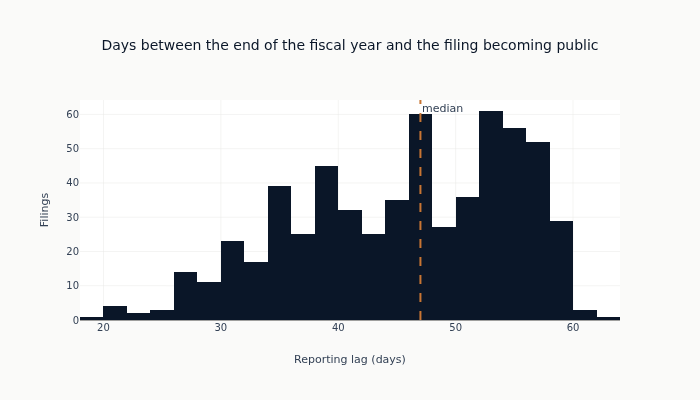

In [5]:
fig = go.Figure(
    go.Histogram(
        x=lag.to_list(),
        marker_color=COLORS["blue"],
        xbins=dict(start=0, end=int(lag.max()) + 5, size=2),
    )
)
fig.add_vline(
    x=lag_median,
    line=dict(color=COLORS["copper"], width=2, dash="dash"),
    annotation_text="median",
)
fig.update_layout(
    title="Days between the end of the fiscal year and the filing becoming public",
    xaxis_title="Reporting lag (days)",
    yaxis_title="Filings",
    height=400,
)
show_plotly_with_alt(
    fig,
    "A histogram of the reporting lag across the corpus, in two-day bins. The mass sits "
    "between roughly thirty and sixty days, with a dashed vertical line marking the median. "
    "No filing falls at or below zero.",
)

## 3. 申报文件的身份标识是 accession number，而不是 ticker

SEC 会为每次提交分配一个 **accession number（准入编号）**，它在所有申报人和所有时间范围内都唯一。ticker 并非以同样方式唯一：拥有两类股份的公司会以两个股票代码进入代码范围 (symbol universe)，而其提交的同一份年报会分别到达一次。

In [6]:
by_accession = filings.group_by("accession_no").agg(
    pl.col("symbol").sort().alias("symbols"),
    pl.col("company_name").first().alias("company"),
    pl.len().alias("rows"),
)
shared = by_accession.filter(pl.col("rows") > 1).sort("company")
shared_rows = int(shared["rows"].sum())
distinct_documents = by_accession.height

display(
    Markdown(f"""
**{shared.height}** filings in the corpus arrive under more than one symbol, accounting for
**{shared_rows}** of the {filings.height:,} rows. Distinct documents:
**{distinct_documents:,}**.
""")
)
shared.select(
    pl.col("company").alias("Company"),
    pl.col("symbols").list.join(", ").alias("Symbols"),
    pl.col("accession_no").alias("Accession number"),
)


**6** filings in the corpus arrive under more than one symbol, accounting for
**12** of the 601 rows. Distinct documents:
**595**.


Company,Symbols,Accession number
str,str,str
"""Alphabet Inc.""","""GOOG, GOOGL""","""0001652044-20-000008"""
"""Alphabet Inc.""","""GOOG, GOOGL""","""0001652044-23-000016"""
"""Alphabet Inc.""","""GOOG, GOOGL""","""0001652044-21-000010"""
"""Alphabet Inc.""","""GOOG, GOOGL""","""0001652044-25-000014"""
"""Alphabet Inc.""","""GOOG, GOOGL""","""0001652044-24-000022"""
"""Alphabet Inc.""","""GOOG, GOOGL""","""0001652044-22-000019"""


### 这对检索器意味着什么代价

如果逐行分块语料库，这些文档中的每一份都会两次进入索引。查询时无法通过相似度发现这种重复，因为两个副本完全相同：检索器在被要求返回前五段文本时，可能把同一段文本返回两次，并将其计为两条相互印证的证据。于是答案会引用两个来源，而它们实际上是一个来源。

在分块前基于 `accession_no` 去重可以消除这种重复。基于 `symbol` 和 `year` 去重则不能，因为两行恰恰在 `symbol` 这个字段上不同。

## 4. 语料库缺失什么

检索系统的失败方式与数据库不同。向数据库请求一行它并不持有的数据，它会返回空；向检索器请求一份它并不持有的文档，它会返回它所持有的最接近的内容，并给出一个看起来平平无奇的相似度分数。缺失必须在查询之前被发现。

In [7]:
coverage = (
    filings.group_by("symbol")
    .agg(pl.col("year").n_unique().alias("years_covered"))
    .sort("years_covered", "symbol")
)
full_span = int(coverage["years_covered"].max())
partial = coverage.filter(pl.col("years_covered") < full_span)
per_year = filings.group_by("year").len().sort("year")

display(
    Markdown(f"""
All but **{partial.height}** of the symbols carry the full **{full_span}** years, and the
count of filings is flat across the span: {", ".join(f"{row['year']} at {row['len']}" for row in per_year.iter_rows(named=True))}.
The exception is
{", ".join(f"`{row['symbol']}`, which carries {row['years_covered']}" for row in partial.iter_rows(named=True))}.

Ask this corpus about that issuer's earlier annual reports and it answers from whichever
documents are nearest in embedding space. Nothing in the answer says the filing was absent,
and nothing in the similarity scores marks it out from an answer drawn from the right
document.
""")
)


All but **1** of the symbols carry the full **6** years, and the
count of filings is flat across the span: 2020 at 100, 2021 at 100, 2022 at 100, 2023 at 100, 2024 at 100, 2025 at 101.
The exception is
`BLK`, which carries 1.

Ask this corpus about that issuer's earlier annual reports and it answers from whichever
documents are nearest in embedding space. Nothing in the answer says the filing was absent,
and nothing in the similarity scores marks it out from an answer drawn from the right
document.


## 5. 存储的文本是什么

存储的文本并不是被截断的申报文件。一份真实的 10-K 长达数十万个字符，而语料库对每份申报文件只存储一个窗口，而不是整份文档。`data/equities/fundamentals/filings_download.py` 中的 `extract_10k_excerpt` 按三条规则中第一条适用者选择窗口：

| 对完整申报文件的条件 | 存储的窗口 | 宽度 |
|---|---|---|
| 出现单词 “supplier” | 从首次出现位置前 3,000 个字符开始 | 12,000 |
| 未出现，且申报文件长度超过 35,000 个字符 | 第 20,000 至 35,000 个字符 | 15,000 |
| 未出现，且申报文件长度短于上述长度 | 开头部分 | 最多 15,000 |

触发了哪条规则并不会记录在该行中。三条规则中有一条会在其处理后的文本中留下痕迹，另外两条不会——这本身就值得测量，而不是假设。

一个测量细节决定了下面的检查能否成立。Polars `str.find` 报告的是**字节**偏移，而这段文本包含弯引号和货币符号，因此只要前面的文本不是纯 ASCII，字节偏移就会越过它本应报告的字符位置，而这些申报文件大多如此。下载代码对 Python 字符串进行切片，而 Python 字符串按字符计数，因此该检查测量的是首次出现位置之前文本的字符长度。

In [8]:
lowered = pl.col("text").str.to_lowercase()
filings = filings.with_columns(
    pl.when(lowered.str.contains(ANCHOR_TERM, literal=True))
    .then(lowered.str.split(ANCHOR_TERM).list.first().str.len_chars())
    .otherwise(None)
    .alias("anchor_offset")
)
anchored = filings.filter(pl.col("anchor_offset").is_not_null())
unanchored = filings.filter(pl.col("anchor_offset").is_null())
fallback = unanchored.filter(pl.col("text_length") == FALLBACK_WINDOW_CHARS)
opening = unanchored.filter(pl.col("text_length") != FALLBACK_WINDOW_CHARS)
at_lead = anchored.filter(pl.col("anchor_offset") == ANCHOR_LEAD_CHARS).height
before_lead = anchored.filter(pl.col("anchor_offset") < ANCHOR_LEAD_CHARS).height
after_lead = anchored.filter(pl.col("anchor_offset") > ANCHOR_LEAD_CHARS).height
anchored_share = anchored.height / filings.height

display(
    Markdown(f"""
**{anchored.height}** of the {filings.height:,} excerpts contain the word "{ANCHOR_TERM}", and
where it sits is not incidental. In **{at_lead}** of them the first occurrence is at character
{ANCHOR_LEAD_CHARS:,} exactly - the lead-in the download keeps. In the other {before_lead} it
comes earlier, which is what happens when the filing's own first occurrence falls inside the
first {ANCHOR_LEAD_CHARS:,} characters and the window has nowhere to start but the beginning.

**{after_lead}** sit later than character {ANCHOR_LEAD_CHARS:,}, and that is the number that
can fail: any excerpt above it would be one the window was not placed on.

So for **{anchored_share:.0%}** of this corpus the stored text is the filing's discussion of
its suppliers and the pages around it. Not the annual report, and not its opening pages.
""")
)


**549** of the 601 excerpts contain the word "supplier", and
where it sits is not incidental. In **544** of them the first occurrence is at character
3,000 exactly - the lead-in the download keeps. In the other 5 it
comes earlier, which is what happens when the filing's own first occurrence falls inside the
first 3,000 characters and the window has nowhere to start but the beginning.

**0** sit later than character 3,000, and that is the number that
can fail: any excerpt above it would be one the window was not placed on.

So for **91%** of this corpus the stored text is the filing's discussion of
its suppliers and the pages around it. Not the annual report, and not its opening pages.


### 另外两条规则无法区分

In [9]:
display(
    Markdown(f"""
The remaining **{filings.height - anchored.height}** excerpts contain no occurrence of
"{ANCHOR_TERM}" anywhere. **{fallback.height}** of them are exactly
{FALLBACK_WINDOW_CHARS:,} characters long and **{opening.height}** are shorter.

Which rule produced the {FALLBACK_WINDOW_CHARS:,}-character group cannot be established from
this corpus. That length is what the mid-document rule always returns, and it is also what
the opening rule returns for any filing between {FALLBACK_WINDOW_CHARS:,} and 35,000
characters. Telling them apart needs the full filing, and the corpus stores the excerpt
instead.

Name that rather than work around it. A pipeline that transforms a document should record the
transform: one column holding which rule fired would turn this from an inference into a
lookup, and would let a retrieval system downstream tell a supplier passage from a slice taken
out of the middle of a document. Nothing in the stored corpus carries that column.
""")
)


The remaining **52** excerpts contain no occurrence of
"supplier" anywhere. **45** of them are exactly
15,000 characters long and **7** are shorter.

Which rule produced the 15,000-character group cannot be established from
this corpus. That length is what the mid-document rule always returns, and it is also what
the opening rule returns for any filing between 15,000 and 35,000
characters. Telling them apart needs the full filing, and the corpus stores the excerpt
instead.

Name that rather than work around it. A pipeline that transforms a document should record the
transform: one column holding which rule fired would turn this from an inference into a
lookup, and would let a retrieval system downstream tell a supplier passage from a slice taken
out of the middle of a document. Nothing in the stored corpus carries that column.


### 按主题选定的语料库限定了什么

本章后面的每一个分块、嵌入和检索结果都是在这批材料上计算得到的。这些比较作为比较仍然有效，因为每一项比较都是在同一文本上运行不同方案——但它们比较的是对采购和供应链文本的检索，而不是对年报的检索。

这给下游解读这些数字带来两个后果。一个在此表现良好的检索器只是在一个主题上表现良好，因此领域嵌入模型相对于通用模型的优势是该主题上的优势，并不会迁移到例如关于收入确认的语料库。并且，这个语料库无法回答的问题并不总是第 4 节意义上的覆盖缺口：申报文件很可能存在，只是被截取到了别处。

这种选择并非偶然。`23_knowledge_graphs/02_supply_chain_kg_construction` 通过同一个加载器调用读取同一语料库，并从中抽取供应商、客户和竞争对手关系，而锚定窗口正是为这项工作提供了相应文本。

## 6. 解析器模式约定

元数据决定一个索引可以服务哪些文档。每份文档如何被拆分为可检索单元是下一个决策，而两种策略界定了这一空间：

- **文本优先（Text-first）**解析会剥离结构并输出单一字符流。速度快且统一，但表格会碎片化，标题会与其章节脱离，分块也没有结构性的内容可供锚定。
- **结构感知（Structure-aware）**解析会保留表格、标题和列表层级。每页速度较慢，但分块可以遵循语义单元，引用也可以解析到章节，而不是字符偏移。

| 解析器模式 | 保留内容 | 主要风险 |
|---|---|---|
| 文本优先（Text-first） | 线性叙述文本 | 表格和章节层级可能丢失 |
| 结构感知（Structure-aware） | 叙述文本、表格、标题、列表 | 提取复杂度更高 |

本 notebook 没有为任一模式附加质量或延迟数字，因为它两者都没有测量。若要支持某种比较，需要一份带标签的样本来涵盖叙述文本、表格、标题和脚注，并在相同文档上测量运行时间。

## 7. 关键要点

In [10]:
display(
    Markdown(f"""
**Filter on the date the document became public.** Every filing here describes a fiscal year
that ended {lag_min} to {lag_max} days before it was published. `period_end` is a
property of the subject matter and `filing_date` is a property of the information set; only
the second one bounds what a decision could have used.

**Key documents by what the publisher made unique.** {shared.height} annual reports in this
corpus arrive under two ticker symbols each, because a dual-class company belongs to the
universe twice. The accession number identifies the submission; the ticker identifies a
listing, and a listing is not a document. An index keyed on the ticker holds those reports
twice and can cite one document as two sources.

**Look for what is missing before you query, not after.** A retriever has no way to answer
"there is no such filing". It returns the nearest documents it holds and scores them
normally, so a coverage hole surfaces as a confident, wrong answer rather than as an error.
The check is a group-by, and it costs nothing next to the cost of not doing it.

**Know what the corpus is an extract of, and what chose the extract.** For
{anchored_share:.0%} of these documents the stored text is a window of at most
{ANCHOR_WINDOW_CHARS:,} characters, taken from {ANCHOR_LEAD_CHARS:,} characters before the
filing's first mention of suppliers, so every
retrieval result later in the chapter is measured over supply-chain prose rather than over
annual reports. That does not invalidate the comparisons, which all run on the same text - it
says what they are comparisons of.

### Known limitations

- The corpus is a fixed download rather than a live feed. It cannot show a filing being
  amended, restated or withdrawn, and a production ingestion pipeline has to handle all
  three.
- `filing_date` is day-level. The SEC records an acceptance timestamp to the second, and a
  strategy acting on the day of a filing needs it: a document accepted after the close was
  not available to trade on that day.
- Coverage is measured in filings per symbol-year. It says nothing about whether the text of
  any particular filing extracted cleanly, which is a question about the parser rather than
  about the corpus.
- The excerpt rule is fixed at download time and cannot be varied here. Measuring how much of
  a retrieval result comes from the topic selection rather than from the retriever would need
  a second corpus cut on a different anchor, which this repository does not ship.

**Next**: [`02_domain_embeddings_comparison`](02_domain_embeddings_comparison.ipynb) embeds
this corpus and asks whether a finance-specific model retrieves it better than a
general-purpose one.
""")
)


**Filter on the date the document became public.** Every filing here describes a fiscal year
that ended 18 to 62 days before it was published. `period_end` is a
property of the subject matter and `filing_date` is a property of the information set; only
the second one bounds what a decision could have used.

**Key documents by what the publisher made unique.** 6 annual reports in this
corpus arrive under two ticker symbols each, because a dual-class company belongs to the
universe twice. The accession number identifies the submission; the ticker identifies a
listing, and a listing is not a document. An index keyed on the ticker holds those reports
twice and can cite one document as two sources.

**Look for what is missing before you query, not after.** A retriever has no way to answer
"there is no such filing". It returns the nearest documents it holds and scores them
normally, so a coverage hole surfaces as a confident, wrong answer rather than as an error.
The check is a group-by, and it costs nothing next to the cost of not doing it.

**Know what the corpus is an extract of, and what chose the extract.** For
91% of these documents the stored text is a window of at most
12,000 characters, taken from 3,000 characters before the
filing's first mention of suppliers, so every
retrieval result later in the chapter is measured over supply-chain prose rather than over
annual reports. That does not invalidate the comparisons, which all run on the same text - it
says what they are comparisons of.

### Known limitations

- The corpus is a fixed download rather than a live feed. It cannot show a filing being
  amended, restated or withdrawn, and a production ingestion pipeline has to handle all
  three.
- `filing_date` is day-level. The SEC records an acceptance timestamp to the second, and a
  strategy acting on the day of a filing needs it: a document accepted after the close was
  not available to trade on that day.
- Coverage is measured in filings per symbol-year. It says nothing about whether the text of
  any particular filing extracted cleanly, which is a question about the parser rather than
  about the corpus.
- The excerpt rule is fixed at download time and cannot be varied here. Measuring how much of
  a retrieval result comes from the topic selection rather than from the retriever would need
  a second corpus cut on a different anchor, which this repository does not ship.

**Next**: [`02_domain_embeddings_comparison`](02_domain_embeddings_comparison.ipynb) embeds
this corpus and asks whether a finance-specific model retrieves it better than a
general-purpose one.
